# Тема 1. Графы знаний, семантические технологии
## Семинар 2. RDF-хранилища и SPARQL

В семинаре 1 граф был построен и записан в Turtle. Теперь этот RDF-граф используется для локальных запросов SPARQL и дальнейшей работы с RDF-хранилищем.

Если второй семинар выполняется отдельно, тот же файл можно скачать ниже

In [1]:
university_ttl_download = '@prefix ex: <http://example.org/semtech/> .\n@prefix rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#> .\n@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .\n@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .\n\nex:ExampleUniversity\n    a ex:University ;\n    rdfs:label "Учебный университет"@ru .\n\nex:AIDepartment\n    a ex:Department ;\n    rdfs:label "Кафедра искусственного интеллекта"@ru ;\n    ex:partOf ex:ExampleUniversity .\n\nex:Petrova\n    a ex:Teacher ;\n    ex:fullName "Елена Петрова"@ru ;\n    ex:worksAt ex:AIDepartment ;\n    ex:teaches ex:SemTech .\n\nex:SemTech\n    a ex:Course ;\n    rdfs:label "Семантические технологии"@ru ;\n    ex:courseCode "ST-101" ;\n    ex:credits 4 .\n\nex:Anna\n    a ex:Student ;\n    ex:fullName "Анна Смирнова"@ru ;\n    ex:enrolledIn ex:SemTech ;\n    ex:memberOf ex:GroupIST41 .\n\nex:Ivan\n    a ex:Student ;\n    ex:fullName "Иван Орлов"@ru ;\n    ex:enrolledIn ex:SemTech ;\n    ex:memberOf ex:GroupIST41 .\n\nex:GroupIST41\n    a ex:StudentGroup ;\n    rdfs:label "ИСТ-41"@ru ;\n    ex:belongsToProgram ex:AppliedInformatics .\n\nex:AppliedInformatics\n    a ex:EducationProgram ;\n    rdfs:label "Прикладная информатика"@ru .\n'

In [2]:
from urllib.parse import quote
from IPython.display import display, HTML

_href = "data:text/turtle;charset=utf-8," + quote(university_ttl_download)
display(HTML(
    '<a download="university.ttl" href="' + _href + '" '
    'style="display:inline-block;padding:8px 12px;border:1px solid #777;'
    'border-radius:6px;text-decoration:none;">'
    'Скачать university.ttl</a>'
))

In [3]:
from IPython.display import display, HTML, SVG
from dataclasses import dataclass
from pathlib import Path
import html as _html
import re

def show_table(headers, rows):
    head = "".join(f"<th>{_html.escape(str(h))}</th>" for h in headers)
    body = []
    for row in rows:
        body.append(
            "<tr>" +
            "".join(f"<td>{_html.escape(str(v))}</td>" for v in row) +
            "</tr>"
        )
    display(HTML(
        '<div style="overflow-x:auto; margin:8px 0 18px 0;">'
        '<table style="border-collapse:collapse; width:100%; font-size:14px;">'
        '<thead><tr>' + head + '</tr></thead>'
        '<tbody>' + "".join(body) + '</tbody></table></div>'
        '<style>'
        'table th, table td {border:1px solid #bbb; padding:7px 9px; vertical-align:top;}'
        'table th {font-weight:600; background:#f5f5f5;}'
        '</style>'
    ))

@dataclass(frozen=True)
class Lit:
    value: object
    lang: str | None = None
    datatype: str | None = None

    def __str__(self):
        if self.lang:
            return f'"{self.value}"@{self.lang}'
        if self.datatype:
            return f'"{self.value}"^^{self.datatype}'
        return str(self.value)

def split_outside_quotes(text, sep):
    parts, buf = [], []
    in_string = False
    escaped = False
    for ch in text:
        if ch == '"' and not escaped:
            in_string = not in_string
        if ch == sep and not in_string:
            parts.append("".join(buf).strip())
            buf = []
        else:
            buf.append(ch)
        escaped = (ch == "\\" and not escaped)
        if ch != "\\":
            escaped = False
    parts.append("".join(buf).strip())
    return [p for p in parts if p]

def parse_object(token):
    token = token.strip()

    # Строка с языком или datatype
    if token.startswith('"'):
        m = re.fullmatch(r'"(.*)"@([A-Za-z-]+)', token)
        if m:
            return Lit(m.group(1), lang=m.group(2))

        m = re.fullmatch(r'"(.*)"\^\^([^\s]+)', token)
        if m:
            return Lit(m.group(1), datatype=m.group(2))

        m = re.fullmatch(r'"(.*)"', token)
        if m:
            return Lit(m.group(1))

    if re.fullmatch(r'-?\d+', token):
        return Lit(int(token), datatype="xsd:integer")

    if re.fullmatch(r'-?\d+\.\d+', token):
        return Lit(float(token), datatype="xsd:decimal")

    if token in {"true", "false"}:
        return Lit(token == "true", datatype="xsd:boolean")

    return token

def parse_course_turtle(text):
    """
    Учебный parser для используемого в курсе подмножества Turtle:
    prefix-строки, a, ;, ,, QNames, строки, language tags, datatypes и числа.
    """
    lines = []
    for raw in text.splitlines():
        line = raw.strip()
        if not line or line.startswith("#") or line.startswith("@prefix"):
            continue
        lines.append(line)

    # Собираем блоки до завершающей точки вне строк.
    blocks, buf = [], []
    in_string = False
    escaped = False
    for line in lines:
        for ch in line + " ":
            if ch == '"' and not escaped:
                in_string = not in_string
            buf.append(ch)
            if ch == "." and not in_string:
                block = "".join(buf[:-1]).strip()
                if block:
                    blocks.append(block)
                buf = []
            escaped = (ch == "\\" and not escaped)
            if ch != "\\":
                escaped = False

    triples = set()

    for block in blocks:
        segments = split_outside_quotes(block, ";")
        if not segments:
            continue

        first = segments[0].split(None, 2)
        if len(first) < 3:
            continue

        subject, pred, obj_text = first
        pred = "rdf:type" if pred == "a" else pred

        for obj in split_outside_quotes(obj_text, ","):
            triples.add((subject, pred, parse_object(obj)))

        for segment in segments[1:]:
            parts = segment.split(None, 1)
            if len(parts) != 2:
                continue
            pred, obj_text = parts
            pred = "rdf:type" if pred == "a" else pred
            for obj in split_outside_quotes(obj_text, ","):
                triples.add((subject, pred, parse_object(obj)))

    return triples

def is_var(x):
    return isinstance(x, str) and x.startswith("?")

def compatible_bind(binding, term, value):
    if is_var(term):
        if term in binding and binding[term] != value:
            return None
        b = dict(binding)
        b[term] = value
        return b
    return dict(binding) if term == value else None

def match_pattern(facts, pattern, input_bindings=None):
    bindings = input_bindings or [dict()]
    out = []
    for b in bindings:
        for fact in facts:
            b1 = compatible_bind(b, pattern[0], fact[0])
            if b1 is None:
                continue
            b2 = compatible_bind(b1, pattern[1], fact[1])
            if b2 is None:
                continue
            b3 = compatible_bind(b2, pattern[2], fact[2])
            if b3 is not None:
                out.append(b3)
    return out

def eval_patterns(facts, patterns):
    bindings = [dict()]
    for p in patterns:
        bindings = match_pattern(facts, p, bindings)
    return bindings

def project(bindings, variables):
    return [[b.get(v, "") for v in variables] for b in bindings]

def ask(facts, patterns):
    return bool(eval_patterns(facts, patterns))

def construct(facts, patterns, template):
    bindings = eval_patterns(facts, patterns)
    out = set()
    for b in bindings:
        for s, p, o in template:
            s2 = b.get(s, s) if is_var(s) else s
            p2 = b.get(p, p) if is_var(p) else p
            o2 = b.get(o, o) if is_var(o) else o
            out.add((s2, p2, o2))
    return out

def simple_rdfs_closure(facts):
    """
    Небольшая демонстрация части RDFS-вывода, достаточная для семинара:
    subClassOf, subPropertyOf, domain и range.
    """
    closure = set(facts)
    changed = True
    while changed:
        changed = False
        new = set()

        subclass = [(s, o) for s, p, o in closure if p == "rdfs:subClassOf"]
        subproperty = [(s, o) for s, p, o in closure if p == "rdfs:subPropertyOf"]
        domains = [(s, o) for s, p, o in closure if p == "rdfs:domain"]
        ranges = [(s, o) for s, p, o in closure if p == "rdfs:range"]
        types = [(s, o) for s, p, o in closure if p == "rdf:type"]

        # Наследование типов по иерархии классов.
        for child, parent in subclass:
            for x, typ in types:
                if typ == child:
                    new.add((x, "rdf:type", parent))

        # Транзитивность subClassOf.
        for a, b in subclass:
            for b2, c in subclass:
                if b == b2:
                    new.add((a, "rdfs:subClassOf", c))

        # Транзитивность subPropertyOf и перенос утверждений на надсвойство.
        for a, b in subproperty:
            for b2, c in subproperty:
                if b == b2:
                    new.add((a, "rdfs:subPropertyOf", c))
        for s, p, o in list(closure):
            for child_p, parent_p in subproperty:
                if p == child_p:
                    new.add((s, parent_p, o))

        # Domain и range порождают типы субъекта и объекта.
        for s, p, o in list(closure):
            for prop, cls in domains:
                if p == prop:
                    new.add((s, "rdf:type", cls))
            if not isinstance(o, Lit):
                for prop, cls in ranges:
                    if p == prop:
                        new.add((o, "rdf:type", cls))

        for t in new:
            if t not in closure:
                closure.add(t)
                changed = True

    return closure

ttl_path = Path("university.ttl")

if ttl_path.exists():
    turtle_source = ttl_path.read_text(encoding="utf-8")
    file_status = "Найден university.ttl в папке notebook."
else:
    turtle_source = university_ttl_download
    file_status = "university.ttl не найден; используется встроенная учебная копия."

facts = parse_course_turtle(turtle_source)

print(file_status)
print("Прочитано учебных RDF-троек:", len(facts))

Найден university.ttl в папке notebook.
Прочитано учебных RDF-троек: 151


**Работа с `.ttl`-файлами на этом семинаре.**

Файл создаётся на Семинаре 1 и здесь используется как исходный RDF-граф для запросов. Файлы занятия: `university.ttl`.

Порядок работы:
1. Поместите нужные `.ttl` рядом с notebook.
2. Если файл был создан на предыдущем семинаре, используйте именно свой вариант.
3. Если файла нет, скачайте учебный образец кнопкой ниже.
4. Запустите ячейку проверки: она покажет, найден ли локальный файл.
5. При наличии локального файла используется он; учебный образец служит только резервом.
6. После редактирования `.ttl` перезапустите notebook с начала, чтобы данные были перечитаны.

In [4]:
from pathlib import Path
from urllib.parse import quote
from IPython.display import display, HTML

def ttl_download_button(filename, text, label=None):
    label = label or f"Скачать учебный образец {filename}"
    href = "data:text/turtle;charset=utf-8," + quote(text)
    display(HTML(
        '<a download="' + filename + '" href="' + href + '" '
        'style="display:inline-block;padding:7px 11px;margin:3px 6px 3px 0;'
        'border:1px solid #777;border-radius:6px;text-decoration:none;">'
        + label + '</a>'
    ))

def ttl_basic_check(text):
    problems = []
    stripped = [line.strip() for line in text.splitlines()
                if line.strip() and not line.strip().startswith("#")]
    if not any(line.startswith("@prefix") or line.upper().startswith("PREFIX") for line in stripped):
        problems.append("Не найдено объявление пространства имён / префикса.")
    if text.count('"') % 2 != 0:
        problems.append("Нечётное число кавычек: возможен незакрытый литерал.")
    return problems

def ttl_file_status(filename, fallback=None):
    p = Path(filename)
    if p.exists():
        text = p.read_text(encoding="utf-8")
        source = "локальный файл"
        found = True
    else:
        text = fallback
        source = "учебный образец" if fallback is not None else "нет данных"
        found = False
    if text is None:
        return {"filename":filename,"found":False,"source":source,"text":None,
                "problems":["Файл отсутствует и учебный образец не задан."]}
    return {"filename":filename,"found":found,"source":source,"text":text,
            "problems":ttl_basic_check(text)}

def show_ttl_status(statuses):
    rows=[]
    for st in statuses:
        rows.append([st["filename"],
                     "найден" if st["found"] else "не найден",
                     st["source"],
                     "OK" if not st["problems"] else "; ".join(st["problems"])])
    if "show_table" in globals():
        show_table(["Файл","В папке notebook","Используется","Базовая проверка"],rows)
    else:
        display(HTML("<pre>" + "\n".join(map(str,rows)) + "</pre>"))

## 1. Semantic Web и модель RDF

**Semantic Web** — подход к публикации и обмену данными, при котором объекты имеют устойчивые идентификаторы, факты представлены в формальной модели, а используемые термины могут однозначно интерпретироваться программами.

RDF задаёт основу такой модели: каждый факт представляется тройкой «субъект — предикат — объект».

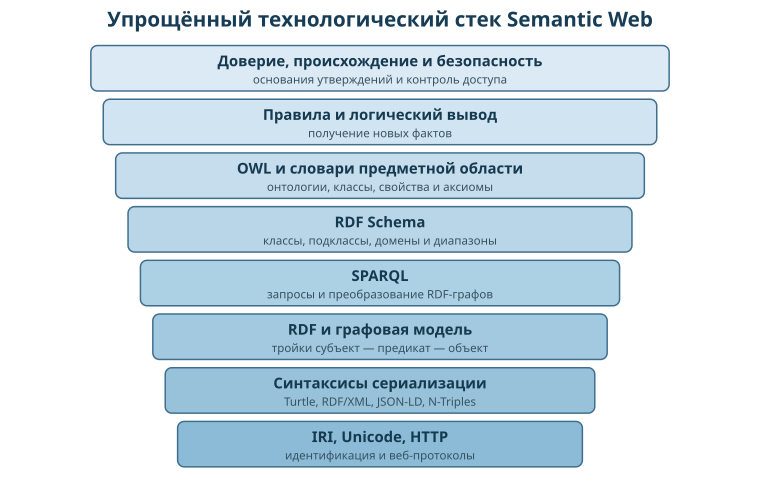

In [5]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="760" height="500" viewBox="0 0 920 605">
  <rect width="920" height="605" fill="white"/>
  <style>
    .b{stroke:#3f6d8c;stroke-width:1.8}
    .t{font:700 18px sans-serif;fill:#15394f;text-anchor:middle}
    .s{font:14px sans-serif;fill:#355160;text-anchor:middle}
    .h{font:700 25px sans-serif;fill:#173c55;text-anchor:middle}
  </style>
  <text x="460" y="32" class="h">Упрощённый технологический стек Semantic Web</text>

  <rect x="110" y="55" width="700" height="55" rx="8" fill="#dceaf5" class="b"/>
  <text x="460" y="80" class="t">Доверие, происхождение и безопасность</text>
  <text x="460" y="101" class="s">основания утверждений и контроль доступа</text>

  <rect x="125" y="120" width="670" height="55" rx="8" fill="#d1e4f2" class="b"/>
  <text x="460" y="145" class="t">Правила и логический вывод</text>
  <text x="460" y="166" class="s">получение новых фактов</text>

  <rect x="140" y="185" width="640" height="55" rx="8" fill="#c5ddec" class="b"/>
  <text x="460" y="210" class="t">OWL и словари предметной области</text>
  <text x="460" y="231" class="s">онтологии, классы, свойства и аксиомы</text>

  <rect x="155" y="250" width="610" height="55" rx="8" fill="#b9d6e8" class="b"/>
  <text x="460" y="275" class="t">RDF Schema</text>
  <text x="460" y="296" class="s">классы, подклассы, домены и диапазоны</text>

  <rect x="170" y="315" width="580" height="55" rx="8" fill="#acd0e4" class="b"/>
  <text x="460" y="340" class="t">SPARQL</text>
  <text x="460" y="361" class="s">запросы и преобразование RDF-графов</text>

  <rect x="185" y="380" width="550" height="55" rx="8" fill="#a2c9df" class="b"/>
  <text x="460" y="405" class="t">RDF и графовая модель</text>
  <text x="460" y="426" class="s">тройки субъект — предикат — объект</text>

  <rect x="200" y="445" width="520" height="55" rx="8" fill="#97c2da" class="b"/>
  <text x="460" y="470" class="t">Синтаксисы сериализации</text>
  <text x="460" y="491" class="s">Turtle, RDF/XML, JSON-LD, N-Triples</text>

  <rect x="215" y="510" width="490" height="55" rx="8" fill="#8bbbd6" class="b"/>
  <text x="460" y="535" class="t">IRI, Unicode, HTTP</text>
  <text x="460" y="556" class="s">идентификация и веб-протоколы</text>
</svg>
"""
display(SVG(svg))

Схема выше показывает основные уровни, на которых данные получают идентификаторы, формальное представление, схему, язык запросов и механизмы вывода.

**IRI и Unicode.** IRI является глобальным идентификатором ресурса. В отличие от локального числового ключа, IRI может использоваться разными организациями. Unicode позволяет применять символы разных языков, хотя на практике локальные имена часто записывают латиницей для совместимости инструментов.

**Сериализации.** RDF является абстрактной моделью, а Turtle, RDF/XML, JSON-LD и N-Triples являются способами записи одного и того же графа. Смена сериализации не должна менять смысл фактов.

**RDF.** RDF задаёт универсальную модель утверждений. Каждый факт представлен как ориентированное подписанное ребро и формально записывается тройкой.

**SPARQL.** SPARQL позволяет искать фрагменты RDF-графа, фильтровать значения, агрегировать результаты и формировать новые графы.

**RDF Schema и OWL.** RDFS описывает базовую иерархию классов и свойств. OWL добавляет более выразительные конструкции: эквивалентность, несовместимость, ограничения кардинальности и логические описания классов.

**Правила, происхождение и доверие.** Система может получать новые факты по правилам, учитывать источник утверждения и применять механизмы контроля. В распределённой среде важны не только смысл факта, но и основание доверия к нему.

**RDF-термы.** Чтобы формально описать RDF-тройку, нужно определить, какие значения разрешены в её трёх позициях. Такие элементы RDF называют **RDF-термами**.

Используются три основных вида RDF-термов:

- **IRI** — глобальный идентификатор ресурса или свойства;
- **пустой узел** — локальный ресурс без собственного IRI;
- **литерал** — конкретное значение: строка, число, дата, логическое значение.

Эти виды термов используются в тройке по-разному:

- субъектом может быть IRI или пустой узел;
- предикатом может быть только IRI;
- объектом может быть IRI, пустой узел или литерал.

Пусть $I$ — множество IRI, $B$ — множество пустых узлов, $L$ — множество литералов. Тогда множество всех допустимых RDF-троек задаётся как

$$
T=(I\cup B)\times I\times(I\cup B\cup L).
$$

RDF-граф - это множество конкретных троек из $T$:

$$
G\subseteq T.
$$

Отдельную RDF-тройку обозначим как

$$
	au=(s,p,o),
$$

где $s$ является субъектом, $p$ является предикатом, а $o$ является объектом.

Например, в тройке

```text
ex:Anna  ex:enrolledIn  ex:SemTech
```

`ex:Anna` — субъект-IRI, `ex:enrolledIn` — предикат-IRI, `ex:SemTech` — объект-IRI.

А в тройке

```text
ex:SemTech  ex:credits  4
```

объект `4` является литералом.

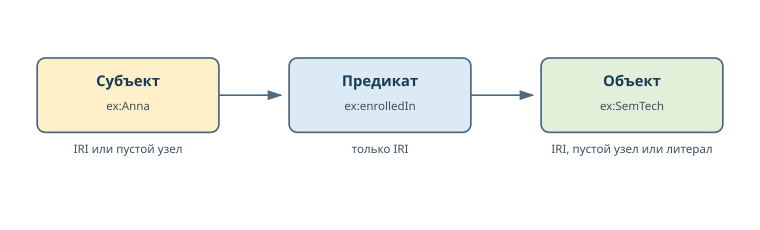

In [6]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="760" height="230" viewBox="0 0 920 278">
  <rect width="920" height="278" fill="white"/>
  <defs>
    <marker id="a" markerWidth="10" markerHeight="10" refX="8" refY="3" orient="auto">
      <path d="M0,0 L0,6 L9,3 z" fill="#506b7f"/>
    </marker>
  </defs>
  <style>
    .n{stroke:#43647b;stroke-width:2}
    .l{font:700 18px sans-serif;fill:#173c55;text-anchor:middle}
    .s{font:14px sans-serif;fill:#3b505d;text-anchor:middle}
    .e{stroke:#506b7f;stroke-width:2;marker-end:url(#a)}
  </style>

  <rect x="45" y="70" width="220" height="90" rx="10" fill="#fff0c9" class="n"/>
  <text x="155" y="104" class="l">Субъект</text>
  <text x="155" y="133" class="s">ex:Anna</text>
  <text x="155" y="185" class="s">IRI или пустой узел</text>

  <rect x="350" y="70" width="220" height="90" rx="10" fill="#dceaf5" class="n"/>
  <text x="460" y="104" class="l">Предикат</text>
  <text x="460" y="133" class="s">ex:enrolledIn</text>
  <text x="460" y="185" class="s">только IRI</text>

  <rect x="655" y="70" width="220" height="90" rx="10" fill="#e2efd9" class="n"/>
  <text x="765" y="104" class="l">Объект</text>
  <text x="765" y="133" class="s">ex:SemTech</text>
  <text x="765" y="185" class="s">IRI, пустой узел или литерал</text>

  <line x1="265" y1="115" x2="340" y2="115" class="e"/>
  <line x1="570" y1="115" x2="645" y2="115" class="e"/>
</svg>
"""
display(SVG(svg))

**IRI.** IRI идентифицирует ресурс или термин словаря. 
Например:

```text
http://example.org/semtech/Anna
```

IRI не обязан открываться в браузере. HTTP-IRI удобны тем, что владелец домена контролирует своё пространство имён и при необходимости может публиковать описание ресурса.

Следует различать:

- IRI сущности `ex:Anna`;
- IRI класса `ex:Student`;
- IRI свойства `ex:enrolledIn`.

Синтаксически все три записи обозначают IRI. Различие определяется тем, как ресурс используется и как он описан схемой.

**Литералы.** Литерал представляет значение: строку, число, дату или логическое значение. Литерал может иметь тип данных или языковую метку.

```turtle
"Анна Смирнова"@ru
"4"^^xsd:integer
"2026-09-01"^^xsd:date
true
```

Языковая метка и явно указанный datatype не применяются одновременно к одному литералу.

**Пустые узлы.** Пустой узел обозначает ресурс без глобального IRI. Он полезен для локальных составных структур. Например, адрес преподавателя можно представить анонимным узлом:

```turtle
ex:Petrova ex:hasAddress [
    ex:city "Москва"@ru ;
    ex:street "Университетская"@ru ;
    ex:building "10"
] .
```

Пустые узлы не следует использовать для важных сущностей, на которые должны ссылаться другие наборы данных: их локальные обозначения не являются устойчивыми глобальными идентификаторами.

**Открытый мир** 

В традиционной прикладной БД отсутствие записи часто трактуется как отрицание. 
В RDF и OWL обычно действует предположение открытого мира: если факт не найден, это ещё не означает, что он ложен. 

$$
\tau\notin G \;\not\Rightarrow\; \neg\tau.
$$

Например, если в графе нет email студента, это означает только, что email не указан в текущих данных.


**Сериализация**

**1. Базовый IRI и префиксы**
```text
    @base <http://example.org/semtech/> .
    @prefix ex:   <http://example.org/semtech/> .
    @prefix rdf:  <http://www.w3.org/1999/02/22-rdf-syntax-ns#> .
    @prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
    @prefix xsd:  <http://www.w3.org/2001/XMLSchema#> .
```
Префикс является синтаксическим сокращением и не создаёт новый объект и не меняет IRI.

**2. Коллекции объектов**
```text
ex:SemTech ex:hasTopic ex:RDF, ex:SPARQL, ex:KnowledgeGraphs 
```
Эта запись соответствует трём тройкам с одинаковыми субъектом и предикатом

**3. Списки**

RDF-список имеет специальную структуру из узлов rdf:first и rdf:rest. 
Turtle предоставляет компактную запись:
```text
ex:SemTech ex:topicSequence ( ex:KnowledgeGraphs ex:RDF ex:SPARQL ).
```
Список следует применять только тогда, когда порядок является частью смысла. Для обычного неупорядоченного множества используется перечисление объектов через запятую.

**4. Именованные графы и наборы данных**

Базовый RDF-граф не содержит имени для каждой тройки. 
Для разделения источников применяются именованные графы. Набор данных состоит из графа по умолчанию и нуля или более именованных графов. 
Именованный граф имеет собственный IRI, что удобно, например, для разделения данных по источникам или версиям.
**TriG** — синтаксис сериализации RDF. По записи он похож на Turtle, но позволяет явно указывать именованные графы. Например:
```trig
ex:catalog2026 {
    ex:SemTech ex:credits 4 .
}

ex:catalog2025 {
    ex:SemTech ex:credits 3 .
}
```
Здесь `ex:catalog2026` и `ex:catalog2025` — два именованных графа с разными версиями значения. TriG нужен только тогда, когда в одном файле требуется хранить несколько графов; для обычного одиночного RDF-графа достаточно Turtle.

## 2. Схема графа, запросы и RDF-хранилище

**RDFS (RDF Schema)** позволяет объявлять классы, свойства, подклассы, подсвойства, домены и диапазоны.

Пример объявления классов и свойства:

```turtle
ex:Student a rdfs:Class .
ex:Course a rdfs:Class .

ex:enrolledIn
    a rdf:Property ;
    rdfs:domain ex:Student ;
    rdfs:range ex:Course ;
    rdfs:label "изучает"@ru .
```

Важно правильно понимать `rdfs:domain` и `rdfs:range`. В RDFS это не только проверочные ограничения, но они задают и правила вывода типов.

Если в графе есть

```turtle
ex:Anna ex:enrolledIn ex:SemTech .
```

и у `ex:enrolledIn` указан домен `ex:Student`, система с RDFS-выводом может получить дополнительный факт

```turtle
ex:Anna a ex:Student .
```

Аналогично `rdfs:range ex:Course` позволяет вывести тип объекта `ex:SemTech`.

Формально правила домена и диапазона можно записать так:

$$
(s,p,o)\land \operatorname{domain}(p,C)
\Rightarrow
(s,\operatorname{rdf:type},C),
$$

$$
(s,p,o)\land \operatorname{range}(p,C)
\Rightarrow
(o,\operatorname{rdf:type},C).
$$

**Правило подкласса.** Если класс $A$ является подклассом $B$, а объект $x$ имеет тип $A$, то выводится тип $B$:

$$
(x,\operatorname{rdf:type},A)\land A\sqsubseteq B
\Rightarrow
(x,\operatorname{rdf:type},B).
$$

Например:

```turtle
ex:GraduateStudent rdfs:subClassOf ex:Student .
ex:Maria a ex:GraduateStudent .
```

позволяет вывести `ex:Maria a ex:Student`.

**Правило подсвойства.** Если свойство $p_1$ является подсвойством $p_2$, то утверждение с $p_1$ порождает утверждение с $p_2$:

$$
(s,p_1,o)\land p_1\sqsubseteq_p p_2
\Rightarrow
(s,p_2,o).
$$

Таким образом, RDFS задаёт не только словарь классов и свойств, но и часть семантики, на основе которой reasoner может получать дополнительные типы и связи.

**SPARQL** — язык запросов к RDF-данным. Запрос задаётся набором шаблонов троек, в которых некоторые позиции заменяются переменными `?name`.

Пусть

$$
P=\{t_1,t_2,\ldots,t_k\},
$$

а $\mu$ — подстановка значений вместо переменных. Решение найдено, если

$$
\mu(P)\subseteq G.
$$

Основные формы:

- `SELECT` — таблица найденных значений;
- `ASK` — `true` или `false`;
- `CONSTRUCT` — новый RDF-граф.

Далее формы запросов показаны на коротких примерах.

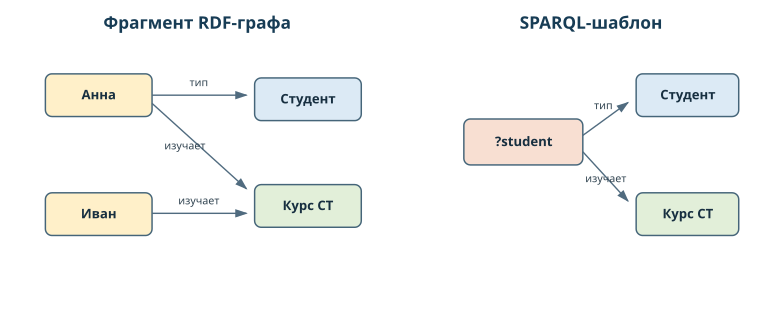

In [7]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="780" height="320" viewBox="0 0 950 390">
  <rect width="950" height="390" fill="white"/>
  <defs>
    <marker id="a" markerWidth="10" markerHeight="10" refX="8" refY="3" orient="auto">
      <path d="M0,0 L0,6 L9,3 z" fill="#506b7f"/>
    </marker>
  </defs>
  <style>
    .n{stroke:#456579;stroke-width:1.8}
    .txt{font:700 16px sans-serif;fill:#172f40;text-anchor:middle}
    .edge{stroke:#506b7f;stroke-width:1.7;marker-end:url(#a)}
    .el{font:13px sans-serif;fill:#2f424f;text-anchor:middle}
    .head{font:700 21px sans-serif;fill:#173c55;text-anchor:middle}
  </style>

  <text x="240" y="35" class="head">Фрагмент RDF-графа</text>
  <text x="720" y="35" class="head">SPARQL-шаблон</text>

  <rect x="55" y="90" width="130" height="52" rx="8" fill="#fff0c9" class="n"/>
  <text x="120" y="121" class="txt">Анна</text>
  <rect x="55" y="235" width="130" height="52" rx="8" fill="#fff0c9" class="n"/>
  <text x="120" y="266" class="txt">Иван</text>

  <rect x="310" y="95" width="130" height="52" rx="8" fill="#dceaf5" class="n"/>
  <text x="375" y="126" class="txt">Студент</text>

  <rect x="310" y="225" width="130" height="52" rx="8" fill="#e2efd9" class="n"/>
  <text x="375" y="256" class="txt">Курс СТ</text>

  <line x1="185" y1="116" x2="300" y2="116" class="edge"/>
  <text x="242" y="105" class="el">тип</text>

  <line x1="185" y1="260" x2="300" y2="260" class="edge"/>
  <text x="242" y="249" class="el">изучает</text>

  <line x1="185" y1="126" x2="300" y2="230" class="edge"/>
  <text x="225" y="182" class="el">изучает</text>

  <rect x="565" y="145" width="145" height="56" rx="8" fill="#f8dfd2" class="n"/>
  <text x="638" y="178" class="txt">?student</text>

  <rect x="775" y="90" width="125" height="52" rx="8" fill="#dceaf5" class="n"/>
  <text x="838" y="121" class="txt">Студент</text>

  <rect x="775" y="235" width="125" height="52" rx="8" fill="#e2efd9" class="n"/>
  <text x="838" y="266" class="txt">Курс СТ</text>

  <line x1="710" y1="165" x2="765" y2="125" class="edge"/>
  <text x="735" y="133" class="el">тип</text>

  <line x1="710" y1="185" x2="765" y2="245" class="edge"/>
  <text x="738" y="222" class="el">изучает</text>
</svg>
"""
display(SVG(svg))

**SELECT** возвращает таблицу найденных подстановок переменных.

```sparql
PREFIX ex: <http://example.org/semtech/>

SELECT ?student ?name
WHERE {
  ?student a ex:Student ;
           ex:fullName ?name ;
           ex:enrolledIn ex:SemTech .
}
ORDER BY ?name
```

`WHERE` содержит графовый шаблон, а `ORDER BY` задаёт порядок строк в результате.

In [8]:
bindings = eval_patterns(facts, [
    ("?student", "rdf:type", "ex:Student"),
    ("?student", "ex:fullName", "?name"),
    ("?student", "ex:enrolledIn", "ex:SemTech"),
])
rows = project(bindings, ["?student", "?name"])
rows.sort(key=lambda x: str(x[1]))
show_table(["student", "name"], rows)

student,name


**ASK** проверяет, существует ли хотя бы одно решение заданного шаблона. Результат — только `true` или `false`.

```sparql
PREFIX ex: <http://example.org/semtech/>

ASK {
  ex:Petrova ex:teaches ex:SemTech .
}
```

Важно: `false` в `ASK` означает, что совпадение не найдено в выбранном графе. При открытом мире это не всегда равнозначно доказанному отрицанию факта.

In [9]:
result = ask(facts, [("ex:Petrova", "ex:teaches", "ex:SemTech")])
show_table(["ASK"], [[str(result).lower()]])

ASK
false


**CONSTRUCT** использует найденные подстановки для построения нового RDF-графа.

```sparql
PREFIX ex: <http://example.org/semtech/>

CONSTRUCT {
  ?course ex:taughtBy ?teacher .
}
WHERE {
  ?teacher ex:teaches ?course .
}
```

Исходный граф при этом не изменяется: `CONSTRUCT` только формирует новый результат в RDF-форме.

In [10]:
new_graph = construct(
    facts,
    [("?teacher", "ex:teaches", "?course")],
    [("?course", "ex:taughtBy", "?teacher")]
)
show_table(["Субъект", "Предикат", "Объект"], sorted(new_graph))

Субъект,Предикат,Объект


**FILTER** добавляет условие к уже найденным решениям. Например, можно оставить только курсы с числом зачётных единиц не меньше четырёх:

```sparql
PREFIX ex: <http://example.org/semtech/>

SELECT ?course ?credits
WHERE {
  ?course a ex:Course ;
          ex:credits ?credits .
  FILTER (?credits >= 4)
}
```

Корректный datatype литерала важен: число `4` и строка `"4"` интерпретируются по-разному.

In [11]:
bindings = eval_patterns(facts, [
    ("?course", "rdf:type", "ex:Course"),
    ("?course", "ex:credits", "?credits"),
])
rows = []
for b in bindings:
    val = b["?credits"]
    if isinstance(val, Lit) and val.datatype == "xsd:integer" and int(val.value) >= 4:
        rows.append([b["?course"], val])
show_table(["course", "credits"], rows)

course,credits


**OPTIONAL** используется, когда свойство желательно получить, но его отсутствие не должно исключать основной результат.

```sparql
PREFIX ex: <http://example.org/semtech/>

SELECT ?student ?name ?email
WHERE {
  ?student a ex:Student ;
           ex:fullName ?name .
  OPTIONAL { ?student ex:email ?email . }
}
```

Студент без email останется в выборке, а переменная `?email` для него будет не связана.

**Агрегация** сворачивает несколько решений в одно итоговое значение. `COUNT` считает строки, а `GROUP BY` задаёт группы:

```sparql
PREFIX ex: <http://example.org/semtech/>

SELECT ?course (COUNT(?student) AS ?studentCount)
WHERE {
  ?student ex:enrolledIn ?course .
}
GROUP BY ?course
ORDER BY DESC(?studentCount)
```

После освоения языка запросов остаётся понять, где физически хранится граф и кто выполняет эти запросы.

In [12]:
base = eval_patterns(facts, [
    ("?student", "rdf:type", "ex:Student"),
    ("?student", "ex:fullName", "?name"),
])
optional_rows = []
for b in base:
    email_matches = eval_patterns(facts, [(b["?student"], "ex:email", "?email")])
    if email_matches:
        optional_rows.append([b["?student"], b["?name"], email_matches[0]["?email"]])
    else:
        optional_rows.append([b["?student"], b["?name"], ""])
show_table(["student", "name", "email"], optional_rows)

enrol = eval_patterns(facts, [("?student", "ex:enrolledIn", "?course")])
counts = {}
for b in enrol:
    counts[b["?course"]] = counts.get(b["?course"], 0) + 1
agg = sorted(counts.items(), key=lambda x: (-x[1], x[0]))
show_table(["course", "studentCount"], agg)

student,name,email
ex:StudentAnna,"""Анна Смирнова""@ru",
ex:StudentIvan,"""Иван Орлов""@ru",


course,studentCount
ex:EnrollmentAnnaKG,1
ex:EnrollmentIvanKG,1
ex:EnrollmentIvanPython,1


**RDF-хранилище (triple store)** - система, оптимизированная для хранения RDF-графов и выполнения SPARQL-запросов. 
Хранилище может работать в памяти, на диске или быть частью распределённой инфраструктуры.

Упрощенная архитектура RDF-хранилища представлена на рисунке. Ее основные элементы включают:

**Парсинг.** При загрузке Turtle парсер проверяет синтаксис и разворачивает компактные имена в полные IRI. Ошибка в точке, кавычке или объявлении префикса может прервать загрузку.

**Словарь идентификаторов.** Длинные IRI и литералы часто кодируются внутренними числовыми ID. Это уменьшает объём индексов и ускоряет сравнение значений.

**Индексы троек.** Для быстрого поиска одни и те же тройки могут индексироваться в нескольких порядках:

- `SPO`: субъект, предикат, объект;
- `POS`: предикат, объект, субъект;
- `OSP`: объект, субъект, предикат.

Шаблон `ex:Anna ?p ?o` удобно искать по индексу, начинающемуся с субъекта. Шаблон `?s ex:enrolledIn ex:SemTech` хорошо соответствует индексу `POS`, потому что предикат и объект уже известны.

**Оптимизатор.** SPARQL-запрос с несколькими шаблонами похож на соединение таблиц. Оптимизатор оценивает селективность шаблонов и старается сначала выполнить тот, который оставляет меньше кандидатов. Если первый шаблон возвращает $n_1$ решений, а второй $n_2$, наивное сопоставление в худшем случае может потребовать порядка

$$
O(n_1\cdot n_2)
$$

проверок совместимости. Индексы и статистика позволяют сократить объём работы.

**SPARQL endpoint** - HTTP-интерфейс для запросов и обновлений. Приложение отправляет текст SPARQL и получает таблицу результатов либо RDF-граф.

**Dataset** - набор RDF-данных, включающий граф по умолчанию и, при необходимости, именованные графы. Endpoint обычно работает с конкретным dataset.

**Транзакции и безопасность.** В промышленной системе важны согласованные изменения, резервное копирование, контроль доступа, журналирование и ограничения ресурсов. Локальный сервер с разрешёнными `SPARQL Update` и административными операциями не следует публиковать в открытой сети без настройки безопасности.

Таким образом, **RDF** описывает данные, **RDFS** задаёт базовую схему и вывод, **SPARQL** формулирует запросы и обновления, а **RDF-хранилище** хранит граф, индексирует его и выполняет операции над ним.

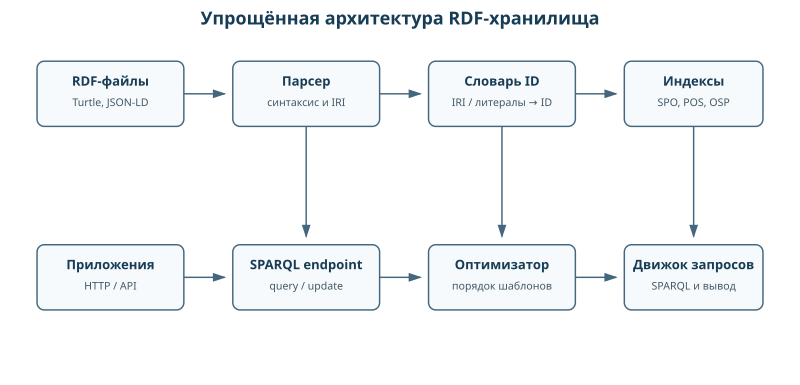

In [13]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="800" height="385" viewBox="0 0 980 472">
  <rect width="980" height="472" fill="white"/>
  <defs>
    <marker id="a" markerWidth="10" markerHeight="10" refX="8" refY="3" orient="auto">
      <path d="M0,0 L0,6 L9,3 z" fill="#45677e"/>
    </marker>
  </defs>
  <style>
    .b{fill:#f7fafc;stroke:#45677e;stroke-width:1.8}
    .t{font:700 16px sans-serif;fill:#173c55;text-anchor:middle}
    .s{font:13px sans-serif;fill:#415765;text-anchor:middle}
    .e{stroke:#45677e;stroke-width:1.8;marker-end:url(#a)}
    .h{font:700 22px sans-serif;fill:#173c55;text-anchor:middle}
  </style>

  <text x="490" y="30" class="h">Упрощённая архитектура RDF-хранилища</text>

  <rect x="45" y="75" width="180" height="80" rx="9" class="b"/>
  <text x="135" y="105" class="t">RDF-файлы</text>
  <text x="135" y="130" class="s">Turtle, JSON-LD</text>

  <rect x="285" y="75" width="180" height="80" rx="9" class="b"/>
  <text x="375" y="105" class="t">Парсер</text>
  <text x="375" y="130" class="s">синтаксис и IRI</text>

  <rect x="525" y="75" width="180" height="80" rx="9" class="b"/>
  <text x="615" y="105" class="t">Словарь ID</text>
  <text x="615" y="130" class="s">IRI / литералы → ID</text>

  <rect x="765" y="75" width="170" height="80" rx="9" class="b"/>
  <text x="850" y="105" class="t">Индексы</text>
  <text x="850" y="130" class="s">SPO, POS, OSP</text>

  <rect x="45" y="300" width="180" height="80" rx="9" class="b"/>
  <text x="135" y="330" class="t">Приложения</text>
  <text x="135" y="355" class="s">HTTP / API</text>

  <rect x="285" y="300" width="180" height="80" rx="9" class="b"/>
  <text x="375" y="330" class="t">SPARQL endpoint</text>
  <text x="375" y="355" class="s">query / update</text>

  <rect x="525" y="300" width="180" height="80" rx="9" class="b"/>
  <text x="615" y="330" class="t">Оптимизатор</text>
  <text x="615" y="355" class="s">порядок шаблонов</text>

  <rect x="765" y="300" width="170" height="80" rx="9" class="b"/>
  <text x="850" y="330" class="t">Движок запросов</text>
  <text x="850" y="355" class="s">SPARQL и вывод</text>

  <line x1="225" y1="115" x2="275" y2="115" class="e"/>
  <line x1="465" y1="115" x2="515" y2="115" class="e"/>
  <line x1="705" y1="115" x2="755" y2="115" class="e"/>

  <line x1="225" y1="340" x2="275" y2="340" class="e"/>
  <line x1="465" y1="340" x2="515" y2="340" class="e"/>
  <line x1="705" y1="340" x2="755" y2="340" class="e"/>

  <line x1="375" y1="155" x2="375" y2="290" class="e"/>
  <line x1="615" y1="155" x2="615" y2="290" class="e"/>
  <line x1="850" y1="155" x2="850" y2="290" class="e"/>
</svg>
"""
display(SVG(svg))

**Обработка SELECT-запроса в RDF-хранилище**

Необходимо различать два алгоритма: 

-внутреннюю обработку запроса хранилищем; 

-последовательность действий при работе с данными. 

Рассмотрим внутреннюю обработку. Упрощённо выполнение `SELECT` можно представить как последовательность следующих действий:

1. принять текст запроса и объявления префиксов;
2. выполнить синтаксический разбор;
3. преобразовать сокращённые имена в полные IRI;
4. построить внутреннее алгебраическое представление запроса;
5. оценить селективность шаблонов по статистике;
6. выбрать порядок сопоставления и подходящие индексы;
7. получить частичные подстановки переменных;
8. соединить совместимые подстановки по общим переменным;
9. применить `FILTER`, `OPTIONAL`, `GROUP BY` и другие операции;
10. оставить переменные, указанные в `SELECT`;
11. сериализовать результат, например в таблицу, JSON или XML.

**Пример** Пусть запрос содержит два шаблона:

```sparql
?student ex:enrolledIn ex:SemTech .
?student ex:fullName ?name .
```

Сначала находятся ресурсы, которые связаны с `ex:SemTech` предикатом `ex:enrolledIn`, затем для каждого найденного `?student` ищется `ex:fullName`. Совместимые решения соединяются по общей переменной `?student`. 
Далее в исполняемых ячейках notebook имитируется данная логика

**Обогащение графа**

Новый факт может появиться тремя основными способами:

1. **Явная загрузка.** Факт введён пользователем или получен из источника и непосредственно записан в граф.
2. **Логический вывод.** Факт следует из схемы или правила. Например, из `GraduateStudent rdfs:subClassOf Student` и типа `Maria a GraduateStudent` выводится тип `Maria a Student`.
3. **Статистическое предсказание.** Модель машинного обучения или графовых эмбеддингов предполагает вероятную связь. Такое предположение не следует автоматически считать доказанным фактом: его нужно хранить вместе с оценкой уверенности и проверять отдельно.

Для практики важно различать явно записанные, логически выведенные и статистически предсказанные утверждения.

**Архитектура приложения на Semantic Web**

Типовой поток Semantic Web-приложения выглядит так:
1. источники предоставляют таблицы, JSON, XML, текст или другие данные;
2. модуль преобразования сопоставляет поля с классами и свойствами;
3. сущности получают IRI;
4. факты представляются в RDF и сериализуются, например, в Turtle;
5. RDF загружается в хранилище;
6. схема и правила при необходимости обогащают граф;
7. приложение обращается к SPARQL endpoint;
8. результаты используются в интерфейсе, аналитике или системе ИИ.

Семантические приложения не обязаны заменять реляционные базы, поисковые индексы и хранилища документов. Их задача - согласовать идентификаторы, смысл и связи между данными.

## 3. Практический цикл работы с RDF-хранилищем

1. подготовить файл Turtle;
2. загрузить или открыть RDF-граф;
3. проверить, что данные прочитаны;
4. сформулировать графовый шаблон;
5. выполнить `SELECT`, `ASK` или `CONSTRUCT`;
6. при необходимости добавить `FILTER`, `OPTIONAL` или агрегацию;
7. выполнить обновление;
8. повторным запросом проверить изменение.

**SPARQL Update** — часть SPARQL, предназначенная для изменения RDF-графа. В семинаре используются `INSERT DATA` для добавления троек и `DELETE WHERE` для удаления найденных троек.

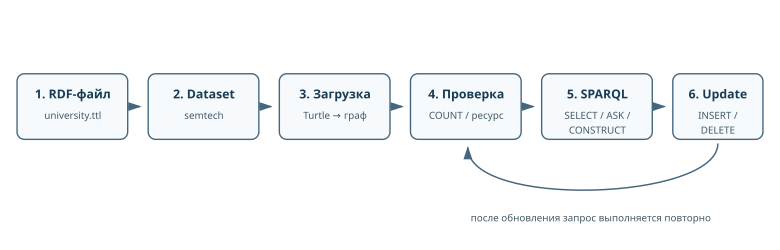

In [14]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="780" height="250" viewBox="0 0 950 305">
  <rect width="950" height="305" fill="white"/>
  <defs>
    <marker id="a" markerWidth="10" markerHeight="10" refX="8" refY="3" orient="auto">
      <path d="M0,0 L0,6 L9,3 z" fill="#45677e"/>
    </marker>
  </defs>
  <style>
    .b{fill:#f7fafc;stroke:#45677e;stroke-width:1.7}
    .t{font:700 15px sans-serif;fill:#173c55;text-anchor:middle}
    .s{font:12px sans-serif;fill:#435967;text-anchor:middle}
    .e{stroke:#45677e;stroke-width:1.8;marker-end:url(#a)}
  </style>

  <rect x="20" y="90" width="135" height="80" rx="9" class="b"/>
  <text x="88" y="120" class="t">1. RDF-файл</text>
  <text x="88" y="145" class="s">university.ttl</text>

  <rect x="180" y="90" width="135" height="80" rx="9" class="b"/>
  <text x="248" y="120" class="t">2. Dataset</text>
  <text x="248" y="145" class="s">semtech</text>

  <rect x="340" y="90" width="135" height="80" rx="9" class="b"/>
  <text x="408" y="120" class="t">3. Загрузка</text>
  <text x="408" y="145" class="s">Turtle → граф</text>

  <rect x="500" y="90" width="135" height="80" rx="9" class="b"/>
  <text x="568" y="120" class="t">4. Проверка</text>
  <text x="568" y="145" class="s">COUNT / ресурс</text>

  <rect x="660" y="90" width="135" height="80" rx="9" class="b"/>
  <text x="728" y="120" class="t">5. SPARQL</text>
  <text x="728" y="145" class="s">SELECT / ASK /</text>
  <text x="728" y="163" class="s">CONSTRUCT</text>

  <rect x="820" y="90" width="110" height="80" rx="9" class="b"/>
  <text x="875" y="120" class="t">6. Update</text>
  <text x="875" y="145" class="s">INSERT /</text>
  <text x="875" y="163" class="s">DELETE</text>

  <line x1="155" y1="130" x2="170" y2="130" class="e"/>
  <line x1="315" y1="130" x2="330" y2="130" class="e"/>
  <line x1="475" y1="130" x2="490" y2="130" class="e"/>
  <line x1="635" y1="130" x2="650" y2="130" class="e"/>
  <line x1="795" y1="130" x2="810" y2="130" class="e"/>

  <path d="M875 175 C875 245, 570 255, 570 180" fill="none" class="e"/>
  <text x="720" y="270" class="s">после обновления запрос выполняется повторно</text>
</svg>
"""
display(SVG(svg))

## 4. Работа с `university.ttl` в notebook

**Шаг 1. Получить файл.** Используйте `university.ttl`, созданный в семинаре 1. Если файла нет, в начале этого notebook есть кнопка его скачивания.

**Шаг 2. Поместить файл рядом с notebook.**

- В JupyterLab/Jupyter Notebook скопируйте `university.ttl` в ту же папку, где находится notebook.
- В JupyterLite загрузите файл через файловую панель слева: **Upload files** → выбрать `university.ttl`.

После этого структура папки должна выглядеть примерно так:

```text
Тема_1_Семинар_2_....ipynb
university.ttl
```

**Шаг 3. Проверить, что файл доступен.**

Скрытая ячейка ниже ищет `university.ttl`. Если файл найден, notebook читает его. Если файл отсутствует, используется встроенная учебная копия того же графа, поэтому примеры всё равно выполняются.

**Шаг 4. Выполнять запросы.** После загрузки файла запускайте ячейки последовательно. Примеры ниже показывают результат `SELECT`, `ASK`, `FILTER`, `CONSTRUCT` и изменения графа.

Если вы заменили `university.ttl` своим файлом, перезапустите notebook с начала, чтобы локальный движок заново прочитал данные.

In [15]:
from pathlib import Path

p = Path("university.ttl")
if p.exists():
    print("Файл найден:", p.name)
    print("Размер:", p.stat().st_size, "байт")
else:
    print("Файл university.ttl не найден в папке notebook.")
    print("Для выполнения примеров используется встроенная копия.")

Файл найден: university.ttl
Размер: 6025 байт


In [16]:
show_table(["tripleCount"], [[len(facts)]])

tripleCount
151


**Запрос 1. Простая выборка.** Получим студентов и их имена.

```sparql
PREFIX ex: <http://example.org/semtech/>

SELECT ?student ?name
WHERE {
  ?student a ex:Student ;
           ex:fullName ?name .
}
ORDER BY ?name
```

Этот запрос проверяет, что мы правильно понимаем типы и свойства исходного графа.

In [17]:
b = eval_patterns(facts, [
    ("?student", "rdf:type", "ex:Student"),
    ("?student", "ex:fullName", "?name"),
])
rows = project(b, ["?student", "?name"])
rows.sort(key=lambda x: str(x[1]))
show_table(["student", "name"], rows)

student,name
ex:StudentAnna,"""Анна Смирнова""@ru"
ex:StudentIvan,"""Иван Орлов""@ru"


**Запрос 2. Направление отношения.** Найдём преподавателя конкретного курса.

```sparql
PREFIX ex: <http://example.org/semtech/>

SELECT ?teacher ?name
WHERE {
  ?teacher a ex:Teacher ;
           ex:fullName ?name ;
           ex:teaches ex:SemTech .
}
```

Если заменить последнюю тройку на `ex:SemTech ex:teaches ?teacher`, результат станет пустым. Это показывает, что направление предиката является частью семантики графа.

In [18]:
correct = eval_patterns(facts, [
    ("?teacher", "rdf:type", "ex:Teacher"),
    ("?teacher", "ex:fullName", "?name"),
    ("?teacher", "ex:teaches", "ex:SemTech"),
])
wrong = eval_patterns(facts, [
    ("ex:SemTech", "ex:teaches", "?teacher"),
])

show_table(["Вариант", "Число решений", "Результат"], [
    ["правильное направление", len(correct), ", ".join(str(x) for x in project(correct, ["?teacher", "?name"])[0]) if correct else ""],
    ["ошибочное направление", len(wrong), ""],
])

Вариант,Число решений,Результат
правильное направление,0,
ошибочное направление,0,


**Запрос 3. Цепочка отношений.** Пройдём от Анны к группе, затем к образовательной программе.

```sparql
PREFIX ex: <http://example.org/semtech/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?program ?programName
WHERE {
  ex:Anna ex:memberOf ?group .
  ?group ex:belongsToProgram ?program .
  ?program rdfs:label ?programName .
}
```

Общая переменная `?group` связывает первые два шаблона в единую цепочку.

In [19]:
b = eval_patterns(facts, [
    ("ex:Anna", "ex:memberOf", "?group"),
    ("?group", "ex:belongsToProgram", "?program"),
    ("?program", "rdfs:label", "?programName"),
])
# Оставляем русскую метку для компактности результата.
rows = [
    [x["?program"], x["?programName"]]
    for x in b
    if isinstance(x["?programName"], Lit) and x["?programName"].lang == "ru"
]
show_table(["program", "programName"], rows)

program,programName
ex:LMSLog20260924,"""Журнал событий LMS за 24 сентября 2026 года""@ru"
ex:CourseKG,"""Графы знаний""@ru"
ex:forCourse,"""запись относится к курсу""@ru"
ex:taughtBy,"""ведётся преподавателем""@ru"
ex:Enrollment,"""Запись на курс""@ru"
ex:providedBy,"""предоставляется организацией""@ru"
ex:hasAssignment,"""содержит задание""@ru"
ex:score,"""результат""@ru"
ex:sourceUrl,"""URL источника""@ru"
ex:CoursePython,"""Основы Python""@ru"


**Запрос 4. ASK.** Проверим наличие совпадения.

```sparql
PREFIX ex: <http://example.org/semtech/>

ASK {
  ex:Anna ex:enrolledIn ex:SemTech .
}
```

Если ресурс отсутствует в графе, ответ будет `false`. При открытом мире это означает отсутствие подтверждения в текущем графе, а не логическое доказательство отрицания.

In [20]:
r1 = ask(facts, [("ex:Anna", "ex:enrolledIn", "ex:SemTech")])
r2 = ask(facts, [("ex:UnknownStudent", "ex:enrolledIn", "ex:SemTech")])
show_table(["Проверка", "ASK"], [
    ["ex:Anna изучает ex:SemTech", str(r1).lower()],
    ["ex:UnknownStudent изучает ex:SemTech", str(r2).lower()],
])

Проверка,ASK
ex:Anna изучает ex:SemTech,false
ex:UnknownStudent изучает ex:SemTech,false


**Запрос 5. FILTER.** Оставим значения, удовлетворяющие числовому условию.

```sparql
PREFIX ex: <http://example.org/semtech/>

SELECT ?course ?credits
WHERE {
  ?course a ex:Course ;
          ex:credits ?credits .
  FILTER (?credits >= 4)
}
```

Если значение `4` ошибочно хранится как строка `"4"`, система уже работает с другим типом данных. Это один из типичных источников неожиданных результатов запросов.

In [21]:
b = eval_patterns(facts, [
    ("?course", "rdf:type", "ex:Course"),
    ("?course", "ex:credits", "?credits"),
])
rows = []
for x in b:
    c = x["?credits"]
    if isinstance(c, Lit) and c.datatype == "xsd:integer" and int(c.value) >= 4:
        rows.append([x["?course"], c])
show_table(["course", "credits"], rows)

course,credits


**Запрос 6. CONSTRUCT.** Построим новый RDF-граф из найденных данных.

```sparql
PREFIX ex: <http://example.org/semtech/>

CONSTRUCT {
  ?course ex:taughtBy ?teacher .
}
WHERE {
  ?teacher ex:teaches ?course .
}
```

Исходный dataset не меняется: результат `CONSTRUCT` существует как отдельный RDF-граф.

In [22]:
cg = construct(
    facts,
    [("?teacher", "ex:teaches", "?course")],
    [("?course", "ex:taughtBy", "?teacher")]
)
show_table(["Субъект", "Предикат", "Объект"], sorted(cg))

Субъект,Предикат,Объект


**Изменение данных.** До этого запросы только читали граф. `SPARQL Update` позволяет менять его.

Добавление нового студента:

```sparql
PREFIX ex: <http://example.org/semtech/>

INSERT DATA {
  ex:Maria
    a ex:Student ;
    ex:fullName "Мария Соколова"@ru ;
    ex:enrolledIn ex:SemTech ;
    ex:memberOf ex:GroupIST41 .
}
```

После `INSERT DATA` нужно повторить `SELECT` и убедиться, что Мария появилась в результате.

Удаление тестового ресурса:

```sparql
PREFIX ex: <http://example.org/semtech/>

DELETE WHERE {
  ex:Maria ?p ?o .
}
```

In [23]:
facts_before = set(facts)
facts.update({
    ("ex:Maria", "rdf:type", "ex:Student"),
    ("ex:Maria", "ex:fullName", Lit("Мария Соколова", lang="ru")),
    ("ex:Maria", "ex:enrolledIn", "ex:SemTech"),
    ("ex:Maria", "ex:memberOf", "ex:GroupIST41"),
})

b = eval_patterns(facts, [
    ("?student", "rdf:type", "ex:Student"),
    ("?student", "ex:fullName", "?name"),
])
rows = project(b, ["?student", "?name"])
rows.sort(key=lambda x: str(x[1]))
show_table(["После INSERT", "name"], rows)

facts = {t for t in facts if t[0] != "ex:Maria"}
print("После DELETE ресурс ex:Maria отсутствует:", not any(t[0] == "ex:Maria" for t in facts))

После INSERT,name
ex:StudentAnna,"""Анна Смирнова""@ru"
ex:StudentIvan,"""Иван Орлов""@ru"
ex:Maria,"""Мария Соколова""@ru"


После DELETE ресурс ex:Maria отсутствует: True


**Проверка RDFS-вывода.** Последний шаг показывает различие между явно записанным и выведенным фактом.

Добавим подкласс и экземпляр:

```turtle
ex:GraduateStudent rdfs:subClassOf ex:Student .
ex:Maria a ex:GraduateStudent .
```

Если RDFS-вывод включён, из этих двух троек следует:

```turtle
ex:Maria a ex:Student .
```

Если вывод отключён, такой тройки в явном графе нет и обычный запрос без учёта схемы её не увидит.

In [24]:
demo = set(facts)
demo.update({
    ("ex:GraduateStudent", "rdfs:subClassOf", "ex:Student"),
    ("ex:Maria", "rdf:type", "ex:GraduateStudent"),
})
explicit = ("ex:Maria", "rdf:type", "ex:Student") in demo
closure = simple_rdfs_closure(demo)
inferred = ("ex:Maria", "rdf:type", "ex:Student") in closure

show_table(["Режим", "Maria rdf:type Student"], [
    ["без RDFS-вывода", str(explicit).lower()],
    ["после RDFS-замыкания", str(inferred).lower()],
])

Режим,Maria rdf:type Student
без RDFS-вывода,false
после RDFS-замыкания,true


## 5. Индивидуальное задание

Каждый студент продолжает работу со своим графом из семинара 1.

**Если `.ttl`-файл уже создан**, поместите его рядом с notebook и используйте в заданиях ниже.

**Если `.ttl`-файла нет**, создайте его перед началом работы:

1. откройте обычный текстовый редактор или новую текстовую ячейку/файл;
2. объявите используемые префиксы;
3. запишите классы, сущности, отношения и атрибуты в Turtle;
4. сохраните файл в кодировке UTF-8 с расширением `.ttl`;
5. поместите файл в ту же папку, что и notebook;
6. перезапустите notebook, чтобы локальный движок прочитал новый файл.

Минимальный шаблон:

```turtle
@prefix ex: <http://example.org/mydata/> .
@prefix rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

ex:Object1
    a ex:SomeClass ;
    rdfs:label "Объект 1"@ru ;
    ex:relatedTo ex:Object2 ;
    ex:numericValue 10 .

ex:Object2
    a ex:AnotherClass ;
    rdfs:label "Объект 2"@ru .
```

После создания файла необходимо выполнить следующую последовательность действий (задание в соответствии с номером $N$ в списке группы):

1. проверить, что notebook его видит;
2. выполнить `COUNT` всех троек;
3. составить не менее трёх `SELECT`-запросов, каждый минимум с двумя шаблонами;
4. выполнить один `ASK`;
5. выполнить один `CONSTRUCT`;
6. выполнить `INSERT DATA` и проверить изменение повторным `SELECT`;
7. применить индивидуальное условие варианта;
8. объяснить результат каждого запроса;
9. намеренно внести одну ошибку направления, IRI или datatype и показать, как изменился результат.


In [25]:
N_STUDENTS = 57

domains = [
    ("Библиотека университета", "книга → выдача → читатель", "год издания", "создать обратное свойство returnedBy/borrowedBy"),
    ("Музейная коллекция", "экспонат → выставка → площадка", "год создания", "сконструировать обратную связь exhibitedObject"),
    ("Онлайн-магазин электроники", "заказ → товар → производитель", "цена", "добавить новый товар через INSERT DATA"),
    ("Поликлиника и запись на приём", "пациент → запись → врач", "дата приёма", "добавить тестовую запись и затем удалить"),
    ("Городской общественный транспорт", "рейс → маршрут → перевозчик", "время отправления", "создать обратную связь servedBy"),
    ("Научные публикации и цитирование", "публикация → журнал → издатель", "год публикации", "сконструировать citedBy"),
    ("Онлайн-платформа обучения", "студент → курс → модуль", "балл/длительность", "добавить новую попытку выполнения"),
    ("Туристические объекты региона", "маршрут → объект → населённый пункт", "рейтинг/год", "создать обратную связь routeIncludes"),
    ("Каталог программного обеспечения", "версия → продукт → разработчик", "дата выпуска", "добавить новую версию"),
    ("Организация конференции", "доклад → секция → зал", "время доклада", "создать обратную связь hasPresentation"),
]

profiles = [
    ("FILTER", "Применить числовой FILTER и сравнить результат при корректном datatype и строковом значении."),
    ("OPTIONAL", "Добавить OPTIONAL для свойства, отсутствующего минимум у одной сущности."),
    ("GROUP BY", "Использовать GROUP BY + COUNT и отсортировать группы по убыванию."),
    ("ASK", "Сформулировать два ASK: один true, один без подтверждения в графе."),
    ("CONSTRUCT", "Построить новый граф с обратным направлением одного отношения."),
    ("PATH-2", "Составить SELECT, требующий перехода минимум по двум объектным отношениям."),
    ("RDFS", "Добавить подкласс и показать различие результата с выводом и без вывода."),
    ("UPDATE", "Добавить новую сущность через INSERT DATA и затем удалить через DELETE WHERE."),
    ("DIAGNOSTIC", "Намеренно изменить направление одного предиката и сравнить число результатов."),
]

rows = []
for i in range(N_STUDENTS):
    domain, path_req, filter_attr, update_req = domains[i % len(domains)]
    operation, requirement = profiles[(i * 3 + i // len(domains)) % len(profiles)]
    rows.append([
        i + 1,
        domain,
        operation,
        path_req,
        filter_attr,
        update_req,
        requirement,
    ])

show_table(
    ["Вариант", "Предметная область", "Обязательная операция",
     "Обязательный путь", "Поле для проверки", "Изменение графа", "Индивидуальное условие"],
    rows,
)

Вариант,Предметная область,Обязательная операция,Обязательный путь,Поле для проверки,Изменение графа,Индивидуальное условие
1,Библиотека университета,FILTER,книга → выдача → читатель,год издания,создать обратное свойство returnedBy/borrowedBy,Применить числовой FILTER и сравнить результат при корректном datatype и строковом значении.
2,Музейная коллекция,ASK,экспонат → выставка → площадка,год создания,сконструировать обратную связь exhibitedObject,"Сформулировать два ASK: один true, один без подтверждения в графе."
3,Онлайн-магазин электроники,RDFS,заказ → товар → производитель,цена,добавить новый товар через INSERT DATA,Добавить подкласс и показать различие результата с выводом и без вывода.
4,Поликлиника и запись на приём,FILTER,пациент → запись → врач,дата приёма,добавить тестовую запись и затем удалить,Применить числовой FILTER и сравнить результат при корректном datatype и строковом значении.
5,Городской общественный транспорт,ASK,рейс → маршрут → перевозчик,время отправления,создать обратную связь servedBy,"Сформулировать два ASK: один true, один без подтверждения в графе."
6,Научные публикации и цитирование,RDFS,публикация → журнал → издатель,год публикации,сконструировать citedBy,Добавить подкласс и показать различие результата с выводом и без вывода.
7,Онлайн-платформа обучения,FILTER,студент → курс → модуль,балл/длительность,добавить новую попытку выполнения,Применить числовой FILTER и сравнить результат при корректном datatype и строковом значении.
8,Туристические объекты региона,ASK,маршрут → объект → населённый пункт,рейтинг/год,создать обратную связь routeIncludes,"Сформулировать два ASK: один true, один без подтверждения в графе."
9,Каталог программного обеспечения,RDFS,версия → продукт → разработчик,дата выпуска,добавить новую версию,Добавить подкласс и показать различие результата с выводом и без вывода.
10,Организация конференции,FILTER,доклад → секция → зал,время доклада,создать обратную связь hasPresentation,Применить числовой FILTER и сравнить результат при корректном datatype и строковом значении.


## 6. Локальный Jupiter

**Порядок работы:**
1. Установите rdflib
  ```text
          !pip install rdflib
  ```
2. В ячейке ноутбука загрузите граф
  ```text
        from rdflib import Graph
        g = Graph()
        g.parse("university.ttl", format="turtle")
        print("Количество троек:", len(g))
  ```
3. Выполните SPARQL-запрос (например, SELECT)

```text
        query = """
        PREFIX ex: <http://example.org/semtech/>
        SELECT ?student ?name
        WHERE {
            ?student a ex:Student ;
                     ex:fullName ?name .
        }
        ORDER BY ?name
        """
        results = g.query(query)
        for row in results:
            print(row.student, row.name)
```
   

4. Аналогично ASK, CONSTRUCT, UPDATE

```text
        # ASK
        ask_query = "ASK { ex:Petrova ex:teaches ex:SemTech . }"
        print(g.query(ask_query).boolAnswer)
    
        # CONSTRUCT
        construct_query = """
        CONSTRUCT { ?course ex:taughtBy ?teacher }
        WHERE { ?teacher ex:teaches ?course }
        """
        new_graph = g.query(construct_query)
        print(len(new_graph))
```  
    
5. Обновление (INSERT/DELETE)

```text
        update = """
        PREFIX ex: <http://example.org/semtech/>
        INSERT DATA {
            ex:Maria a ex:Student ;
                     ex:fullName "Мария Соколова"@ru ;
                     ex:enrolledIn ex:SemTech .
        }
        """
        g.update(update)
``` 

## 7. Apache Jena Fuseki

**Apache Jena Fuseki** — отдельный SPARQL-сервер. В отличие от локального учебного режима notebook, Fuseki работает как настоящее RDF-хранилище: принимает RDF-файлы, хранит dataset и предоставляет SPARQL endpoint по HTTP.

Использовать Fuseki имеет смысл после того, как локальные запросы уже понятны.

**Порядок работы:**

1. установить Java 21 или новее;
2. скачать актуальный архив Apache Jena Fuseki и распаковать его;
3. запустить `fuseki-server` (`fuseki-server.bat` в Windows);
4. открыть в браузере

```text
http://localhost:3030/
```

5. нажать **Add one**;
6. выбрать **in-memory**;
7. задать имя dataset, например `semtech`;
8. открыть **add data**;
9. загрузить `university.ttl`;
10. открыть вкладку Query и выполнить те же SPARQL-запросы, которые использовались в notebook.

После создания dataset `semtech` его SPARQL endpoint имеет вид:

```text
http://localhost:3030/semtech/sparql
```

Для публикации готового RDF-файла только для запросов можно запустить:

```text
fuseki-server --file university.ttl /semtech
```

Для постоянного TDB2-хранилища:

```text
fuseki-server --loc=data /semtech
```


## 8. Решение индивидуального задания — вариант 57

### 8.1. Условие и подготовка

**Предметная область:** онлайн-платформа обучения.  
**Обязательная операция:** `GROUP BY + COUNT` с сортировкой групп по убыванию.  
**Обязательный путь:** студент → курс → модуль. В модели Семинара 1 запись на курс представлена самостоятельной сущностью, поэтому фактический путь имеет вид `Student → Enrollment → Course → Module`.  
**Поле для проверки:** балл попытки (`ex:score`, `xsd:decimal`).  
**Изменение графа:** добавить новую попытку выполнения задания через `INSERT DATA`.

Ниже используется файл `university.ttl`, созданный в Семинаре 1 для варианта 57. Все изменения выполняются в оперативной копии графа `g57`; исходный файл не перезаписывается.


In [26]:
from pathlib import Path

try:
    from rdflib import Graph, Namespace, RDF, RDFS, XSD
except ImportError as exc:
    raise ImportError("Для выполнения индивидуального задания установите rdflib: pip install rdflib") from exc

ttl_path57 = Path("university.ttl")
if not ttl_path57.exists():
    raise FileNotFoundError("Файл university.ttl должен находиться рядом с notebook.")

g57 = Graph()
g57.parse(ttl_path57, format="turtle")
EX57 = Namespace("http://example.org/semtech/variant57/")
count_query57 = """
SELECT (COUNT(*) AS ?tripleCount)
WHERE { ?subject ?predicate ?object . }
"""
sparql_count57 = int(next(iter(g57.query(count_query57))).tripleCount)
initial_triple_count57 = len(g57)

show_table(
    ["Проверка", "Результат"],
    [
        ["Файл", str(ttl_path57.resolve())],
        ["Синтаксис Turtle", "корректен (rdflib)"],
        ["SPARQL COUNT всех троек", sparql_count57],
    ],
)

assert sparql_count57 == initial_triple_count57 == 151


Проверка,Результат
Файл,C:\Users\nasty\Semantic_technologies\university.ttl
Синтаксис Turtle,корректен (rdflib)
SPARQL COUNT всех троек,151


### 8.2. SELECT-запросы

Каждый запрос содержит не менее двух шаблонов троек. Первый реализует обязательный объектный путь, второй проверяет числовой тип и фильтрацию баллов, третий раскрывает структуру курсов.


In [27]:
def short57(value):
    text = str(value)
    return text.rsplit("/", 1)[-1].rsplit("#", 1)[-1]


def rows57(result, fields):
    return [[str(getattr(row, field)) if getattr(row, field) is not None else "—" for field in fields]
            for row in result]


# SELECT 1: обязательный путь Student -> Enrollment -> Course -> Module.
select_path57 = """
PREFIX ex: <http://example.org/semtech/variant57/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
SELECT ?studentName ?courseCode ?moduleName
WHERE {
  ?student a ex:Student ;
           ex:fullName ?studentName ;
           ex:enrolledIn ?enrollment .
  ?enrollment ex:forCourse ?course .
  ?course ex:courseCode ?courseCode ;
          ex:hasModule ?module .
  ?module rdfs:label ?moduleName .
  FILTER(LANG(?studentName) = "ru" && LANG(?moduleName) = "ru")
}
ORDER BY ?studentName ?courseCode
"""
path_rows57 = rows57(g57.query(select_path57), ["studentName", "courseCode", "moduleName"])
show_table(["Студент", "Курс", "Модуль"], path_rows57)


# SELECT 2: попытки с корректным xsd:decimal и баллом не ниже 0.80.
select_scores57 = """
PREFIX ex: <http://example.org/semtech/variant57/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
SELECT ?studentName ?attempt ?assignmentName ?score ?date
WHERE {
  ?student ex:fullName ?studentName ;
           ex:submittedAttempt ?attempt .
  ?attempt ex:attemptForAssignment ?assignment ;
           ex:score ?score ;
           ex:submittedOn ?date .
  ?assignment rdfs:label ?assignmentName .
  FILTER(LANG(?studentName) = "ru" && LANG(?assignmentName) = "ru")
  FILTER(DATATYPE(?score) = xsd:decimal && ?score >= 0.80)
}
ORDER BY DESC(?score)
"""
score_result57 = list(g57.query(select_scores57))
score_rows57 = [
    [str(row.studentName), short57(row.attempt), str(row.assignmentName), str(row.score), str(row.date)]
    for row in score_result57
]
show_table(["Студент", "Попытка", "Задание", "Балл", "Дата"], score_rows57)


# SELECT 3: структура Course -> Module -> Assignment.
select_structure57 = """
PREFIX ex: <http://example.org/semtech/variant57/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
SELECT ?courseCode ?moduleName ?assignmentName
WHERE {
  ?course ex:courseCode ?courseCode ;
          ex:hasModule ?module .
  ?module rdfs:label ?moduleName ;
          ex:hasAssignment ?assignment .
  ?assignment rdfs:label ?assignmentName .
  FILTER(LANG(?moduleName) = "ru" && LANG(?assignmentName) = "ru")
}
ORDER BY ?courseCode
"""
structure_rows57 = rows57(
    g57.query(select_structure57),
    ["courseCode", "moduleName", "assignmentName"],
)
show_table(["Курс", "Модуль", "Задание"], structure_rows57)


Студент,Курс,Модуль
Анна Смирнова,KG-101,RDF и Turtle
Иван Орлов,KG-101,RDF и Turtle
Иван Орлов,PY-100,Функции Python


Студент,Попытка,Задание,Балл,Дата
Анна Смирнова,AttemptAnnaKG2,Построить RDF-граф,0.91,2026-09-24
Иван Орлов,AttemptIvanPython1,Реализовать функцию,0.88,2026-09-22
Иван Орлов,AttemptIvanKG1,Построить RDF-граф,0.84,2026-09-23


Курс,Модуль,Задание
KG-101,RDF и Turtle,Построить RDF-граф
PY-100,Функции Python,Реализовать функцию


### 8.3. Индивидуальная операция: GROUP BY + COUNT

Запрос проходит от курса к заданию, затем к попытке и отправившему её студенту. `COUNT(DISTINCT ?attempt)` исключает случайный двойной подсчёт, а `ORDER BY DESC(?attemptCount)` размещает курс с наибольшим числом попыток первым.


In [28]:
group_query57 = """
PREFIX ex: <http://example.org/semtech/variant57/>
SELECT ?courseCode (COUNT(DISTINCT ?attempt) AS ?attemptCount)
WHERE {
  ?course ex:courseCode ?courseCode ;
          ex:hasModule ?module .
  ?module ex:hasAssignment ?assignment .
  ?attempt ex:attemptForAssignment ?assignment .
  ?student ex:submittedAttempt ?attempt .
}
GROUP BY ?courseCode
ORDER BY DESC(?attemptCount) ?courseCode
"""

group_before57 = [[str(row.courseCode), int(row.attemptCount)] for row in g57.query(group_query57)]
show_table(["Курс", "Количество попыток"], group_before57)
assert group_before57 == [["KG-101", 3], ["PY-100", 1]]


Курс,Количество попыток
KG-101,3
PY-100,1


### 8.4. ASK и CONSTRUCT

`ASK` проверяет наличие отдельного ресурса-источника у второй попытки Анны. `CONSTRUCT` строит новый граф с обратным отношением `ex:submittedBy`; исходный граф при этом не изменяется.


In [29]:
ask_query57 = """
PREFIX ex: <http://example.org/semtech/variant57/>
ASK {
  ex:AttemptAnnaKG2 ex:hasSource ?source .
  ?source a ex:Source ; ex:sourceUrl ?url .
}
"""
ask_answer57 = bool(g57.query(ask_query57).askAnswer)

construct_query57 = """
PREFIX ex: <http://example.org/semtech/variant57/>
CONSTRUCT {
  ?attempt ex:submittedBy ?student .
}
WHERE {
  ?student a ex:Student ;
           ex:submittedAttempt ?attempt .
  ?attempt a ex:Attempt .
}
"""
inverse_graph57 = g57.query(construct_query57).graph
inverse_rows57 = sorted(
    [[short57(s), short57(p), short57(o)] for s, p, o in inverse_graph57],
    key=lambda row: (row[0], row[2]),
)

show_table(["ASK", "Ответ"], [["У AttemptAnnaKG2 указан отдельный источник?", str(ask_answer57).lower()]])
show_table(["Попытка", "Новое отношение", "Студент"], inverse_rows57)

assert ask_answer57 is True
assert len(inverse_graph57) == 4
assert len(g57) == initial_triple_count57


ASK,Ответ
У AttemptAnnaKG2 указан отдельный источник?,true


Попытка,Новое отношение,Студент
AttemptAnnaKG1,submittedBy,StudentAnna
AttemptAnnaKG2,submittedBy,StudentAnna
AttemptIvanKG1,submittedBy,StudentIvan
AttemptIvanPython1,submittedBy,StudentIvan


### 8.5. INSERT DATA и повторная проверка

В оперативный граф добавляется третья попытка Анны по заданию `AssignmentRDF`. Новая попытка получает тип, связь с заданием, балл `0.95` типа `xsd:decimal`, дату, порядковый номер и связь со студентом. Затем отдельный `SELECT` подтверждает вставку, а агрегат выполняется повторно.


In [30]:
insert_query57 = """
PREFIX ex: <http://example.org/semtech/variant57/>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
INSERT DATA {
  ex:AttemptAnnaKG3 a ex:Attempt ;
      ex:attemptForAssignment ex:AssignmentRDF ;
      ex:score "0.95"^^xsd:decimal ;
      ex:submittedOn "2026-09-28"^^xsd:date ;
      ex:attemptNumber "3"^^xsd:integer .
  ex:StudentAnna ex:submittedAttempt ex:AttemptAnnaKG3 .
}
"""
g57.update(insert_query57)
after_insert_count57 = len(g57)

verify_insert57 = """
PREFIX ex: <http://example.org/semtech/variant57/>
SELECT ?attempt ?score ?date
WHERE {
  ex:StudentAnna ex:submittedAttempt ?attempt .
  ?attempt a ex:Attempt ;
           ex:score ?score ;
           ex:submittedOn ?date .
  FILTER(?attempt = ex:AttemptAnnaKG3)
}
"""
insert_rows57 = [
    [short57(row.attempt), str(row.score), str(row.date)]
    for row in g57.query(verify_insert57)
]
group_after57 = [[str(row.courseCode), int(row.attemptCount)] for row in g57.query(group_query57)]

show_table(
    ["Показатель", "До INSERT", "После INSERT"],
    [
        ["Число троек", initial_triple_count57, after_insert_count57],
        ["Попытки KG-101", group_before57[0][1], group_after57[0][1]],
    ],
)
show_table(["Добавленная попытка", "Балл", "Дата"], insert_rows57)

assert after_insert_count57 == initial_triple_count57 + 6
assert insert_rows57 == [["AttemptAnnaKG3", "0.95", "2026-09-28"]]
assert group_after57 == [["KG-101", 4], ["PY-100", 1]]


Показатель,До INSERT,После INSERT
Число троек,151,157
Попытки KG-101,3,4


Добавленная попытка,Балл,Дата
AttemptAnnaKG3,0.95,2026-09-28


### 8.6. Диагностика намеренной ошибки

В корректной модели `submittedAttempt` направлен от студента к попытке. Ошибочный запрос меняет направление на обратное. Поскольку RDF не предполагает автоматической симметрии свойства, ошибочный запрос возвращает ноль строк — это не означает отсутствия попыток, а указывает на неверный графовый шаблон.


In [31]:
correct_direction57 = """
PREFIX ex: <http://example.org/semtech/variant57/>
SELECT ?student ?attempt
WHERE {
  ?student a ex:Student ; ex:submittedAttempt ?attempt .
  ?attempt a ex:Attempt .
}
"""

wrong_direction57 = """
PREFIX ex: <http://example.org/semtech/variant57/>
SELECT ?student ?attempt
WHERE {
  ?student a ex:Student .
  ?attempt a ex:Attempt ; ex:submittedAttempt ?student .
}
"""

correct_count57 = len(list(g57.query(correct_direction57)))
wrong_count57 = len(list(g57.query(wrong_direction57)))
show_table(
    ["Шаблон", "Число результатов", "Объяснение"],
    [
        ["Student —submittedAttempt→ Attempt", correct_count57, "корректное направление"],
        ["Attempt —submittedAttempt→ Student", wrong_count57, "намеренная ошибка направления"],
    ],
)

assert correct_count57 == 5
assert wrong_count57 == 0


Шаблон,Число результатов,Объяснение
Student —submittedAttempt→ Attempt,5,корректное направление
Attempt —submittedAttempt→ Student,0,намеренная ошибка направления


### 8.7. Выводы по запросам

- Исходный Turtle-граф содержит **151 тройку**.
- Путь `Student → Enrollment → Course → Module` показывает, что Анна связана с курсом `KG-101`, а Иван — с `KG-101` и `PY-100`.
- Числовой `FILTER` по корректному `xsd:decimal` до обновления находит три попытки с баллом не ниже `0.80`.
- Агрегация до обновления возвращает `KG-101 — 3` и `PY-100 — 1`; после вставки новой попытки — `KG-101 — 4` и `PY-100 — 1`.
- `ASK` возвращает `true`, потому что в графе есть ресурс-источник `LMSLog20260924`.
- `CONSTRUCT` создаёт четыре обратные тройки `Attempt → submittedBy → Student`, не меняя исходный граф.
- `INSERT DATA` добавляет шесть троек и увеличивает граф со 151 до **157 троек**.
- Ошибочное направление `Attempt → submittedAttempt → Student` даёт 0 результатов вместо 5 и демонстрирует, почему направление RDF-предиката существенно.
